# NDT-Transformer on KITTI: experiments

Runtime -> Change runtime type -> **T4 GPU** (or better). Set cell 1, then **Runtime -> Run all**.
`MODE` in cell 1 says what this run is for (train / eval / smoke); every cell does only what that mode needs
and skips work that is already done, so Run all is also right after a disconnect or in a new session.

- **NDT variant** (preprocessing + G): `MyDrive/lpr/ndt/<variant>/` with `config.json`, one cells tar and one stats file per sequence.
- **Run** (training): `MyDrive/lpr/runs/ndt/<run>/` with `config.json`, `metrics.csv` and a checkpoint per epoch.
- **Evaluations** (`EVALS`, types in `src/lpr/evals.py`): `MyDrive/lpr/runs/ndt/<run>/eval/<type>/<checkpoint>/`.
  `seqs_heading`: recall on every sequence + query headings; `tnet`: what the T-Net learned;
  `compass`: map and queries rotated to one orientation by the pose heading, queries with a Gaussian compass error.
- Tables of everything: `MyDrive/lpr/runs_summary.csv` (runs) and `MyDrive/lpr/evals_summary.csv` (evaluations).

Names: `<date>_baseline_<hash>` for the default parameters, otherwise `<date>_<tag>_<hash>` or `<date>_<hash>`.

## 1. Settings

In [ ]:
REPO_URL = "https://github.com/dov85/lidar-place-recognition"
DRIVE = "/content/drive/MyDrive/lpr"
SEQ = "00"                          # training sequence
# What this run of the notebook does. "Runtime -> Run all" works in every mode:
#   "train": data, training (a new run, or the continuation of an unfinished one; a finished run
#            is not trained again), then the evaluations
#   "eval":  only the evaluations of an existing run (nothing is trained or built)
#   "smoke": a short training test (time and GPU memory), nothing is saved to Drive
MODE = "train"
EVAL_CKPT = "last"                  # "last" or a checkpoint file of the run, e.g. "epoch_18.pth"
# EVALS types: seqs_heading, compass, tnet (NDT-Transformer only), sparsity (32 / 16 beams;
# the sparse variants are built on Azure, see the README)
EVALS = ['seqs_heading', 'tnet', 'compass']   # types in src/lpr/evals.py (EVAL_TYPES)

# NDT variant: only what differs from the defaults (src/lpr/experiments.py, NDT_DEFAULTS):
#   crop="square", half_size=40.0, ground="patchwork", k=2000, over=0.10, radius=0.8,
#   min_pts=5, knn=8, cov_eps=1e-3
NDT_TAG = ""          # name for a changed variant; empty = date + hash
NDT_PARAMS = dict()                 # e.g. dict(crop="circle", radius=1.0)

# Training run: only what differs from the defaults (TRAIN_DEFAULTS):
#   pos_thr=5.0, neg_thr=7.0, epochs=20, lr=1e-5, milestones=[9, 15], batch_queries=2,
#   positives=2, negatives=18, margin1=0.5, margin2=0.2, hard_neg_after_epoch=5, amp=True, seed=0,
#   cov_transform=False  (True: the T-Net also transforms the covariances, as in the paper),
#   rot_aug=False        (True: every training cloud rotated about z by its own random angle)
#   rot_points=0         (N > 0: every training cloud taken from one of N copies of its scan whose raw
#                         points were rotated by a random angle before the cells were built; the copies
#                         are built on Azure once per variant and N, see section 4)
RUN_TAG = ""          # name for a changed run; empty = date + hash
TRAIN_PARAMS = dict(cov_transform=True,rot_points=8)               # e.g. dict(lr=5e-6, negatives=12)

KITTI = "/content/kitti"                       # poses (+ raw scans when a variant is built here)
RAW_TAR = f"{DRIVE}/kitti_seq00_raw.tar"     # backup of the raw scans of sequence 00

## 2. Drive, GPU, code, poses, Drive layout

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')
import os, sys, json, subprocess, importlib, glob
assert MODE in ("train", "eval", "smoke"), MODE
os.makedirs(DRIVE, exist_ok=True)
!nvidia-smi --query-gpu=name,memory.total --format=csv

url = REPO_URL
try:  # private repo: store a token in Colab Secrets as GITHUB_TOKEN
    url = REPO_URL.replace("https://", f"https://{userdata.get('GITHUB_TOKEN')}@")
except Exception:
    pass
if not os.path.exists("/content/lpr"):
    subprocess.run(["git", "clone", "-q", url, "/content/lpr"], check=True)
else:
    subprocess.run(["git", "-C", "/content/lpr", "pull", "-q"], check=True)
%cd /content/lpr
!git log --oneline -1
!bash scripts/setup_third_party.sh
!pip install -q -r requirements.txt

sys.path.insert(0, "/content/lpr/src")
import lpr.experiments as ex, lpr.evals as ev
importlib.reload(ex); importlib.reload(ev)
missing_poses = [s for s in ev.ALL_SEQS if not os.path.exists(f"{KITTI}/poses/{s}.txt")]
if missing_poses:
    !python scripts/download_kitti.py --out {KITTI} --seqs {" ".join(missing_poses)} --poses_only

# older results into the current Drive layout (does nothing once done)
if os.path.exists(f"{DRIVE}/runs/ndt_kitti00"):
    !python scripts/migrate_stage1.py --drive {DRIVE} --apply
!python scripts/migrate_layout.py --drive {DRIVE} --apply

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB
/content/lpr
4471fe6 (HEAD -> main, origin/main, origin/HEAD) Created using Colab
third_party/NDT-Transformer @ 51f90df
third_party/BEVPlace2 @ 2d0636d5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.9/249.9 kB 18.3 MB/s eta 0:00:00
poses + calib ...
poses -> /content/kitti/poses
nothing to migrate


## 3. Names of the NDT variant and the run

In [ ]:
VARIANT, NDT_FULL, ndt_exists = ex.resolve_ndt_variant(DRIVE, NDT_PARAMS, NDT_TAG)
VDIR = f"{DRIVE}/ndt/{VARIANT}"          # permanent copy on Drive
NDT = f"/content/ndt/{VARIANT}"          # working copy on this machine
CELLS_TAR = f"{VDIR}/cells_{SEQ}.tar"

RUN, TRAIN_FULL, run_state = ex.resolve_run(DRIVE, dict(TRAIN_PARAMS, seq=SEQ), VARIANT, RUN_TAG)
RUN_DIR = f"{DRIVE}/runs/ndt/{RUN}"
print("mode:       ", MODE)
print("NDT variant:", VARIANT, "(on Drive)" if ndt_exists else "(new)")
print(json.dumps(NDT_FULL))
print("run:        ", RUN, f"({run_state})")
print(json.dumps(TRAIN_FULL))
if MODE == "eval" and run_state == "new":
    raise SystemExit("MODE = 'eval', but there is no run with these parameters: check TRAIN_PARAMS / NDT_PARAMS")

t = TRAIN_FULL
train_args = (f"--ndt_dir {NDT} --kitti_root {KITTI} --train_pickle {NDT}/train_{SEQ}.pickle "
              f"--ndt_variant {VARIANT} --seq {SEQ} --epochs {t['epochs']} --lr {t['lr']} "
              f"--milestones {' '.join(map(str, t['milestones']))} --batch_queries {t['batch_queries']} "
              f"--positives {t['positives']} --negatives {t['negatives']} --margin1 {t['margin1']} "
              f"--margin2 {t['margin2']} --hard_neg_after_epoch {t['hard_neg_after_epoch']} --seed {t['seed']}"
              + (" --amp" if t["amp"] else "") + (" --cov_transform" if t["cov_transform"] else "")
              + (" --rot_aug" if t["rot_aug"] else "")
              + (f" --rot_points {t['rot_points']}" if t["rot_points"] else ""))

mode:        train
NDT variant: 2026-10-04_baseline_717e81 (on Drive)
{"crop": "square", "half_size": 40.0, "ground": "patchwork", "k": 2000, "over": 0.1, "radius": 0.8, "min_pts": 5, "knn": 8, "cov_eps": 0.001}
run:         2026-10-12_e39427 (new)
{"seq": "00", "pos_thr": 5.0, "neg_thr": 7.0, "epochs": 20, "lr": 1e-05, "milestones": [9, 15], "batch_queries": 2, "positives": 2, "negatives": 18, "margin1": 0.5, "margin2": 0.2, "hard_neg_after_epoch": 5, "amp": true, "seed": 0, "cov_transform": true, "rot_aug": false, "rot_points": 8}


## 4. NDT cells of the training sequence: restore from Drive, or build the variant
Building restores the raw scans from `RAW_TAR` (or downloads them) and runs preprocessing + G on every scan
(about 0.5 s per scan on 2 CPU cores). In `eval` mode nothing is built.
Every build also runs the built-in checks: coverage of the points by the cells (columns `cov_0.8`, `dense_cov`, ...
in `stats_<seq>.csv`) and pictures of 10 random scans in `<variant>/previews_<seq>/`; notebook 03 shows them.

With `rot_points=N` in `TRAIN_PARAMS` (train / smoke): the N point-rotated copies of the training frames
(`cells_<seq>_rot<N>.tar` of the variant) are copied from the Azure blob container to Drive, and from Drive
to this machine. If they are not built yet, this cell prints the command for the Azure VM and stops.

In [ ]:
from IPython.display import Image, display
ndt_args = " ".join(f"--{k} {v}" for k, v in NDT_FULL.items())

if os.path.exists(f"{NDT}/{SEQ}/000000.bin"):
    print("NDT cells already on this machine:", NDT)
elif os.path.exists(CELLS_TAR):
    os.makedirs(NDT, exist_ok=True)
    !tar -xf {CELLS_TAR} -C {NDT}
    !cp {VDIR}/config.json {NDT}/config.json
elif MODE == "eval":
    print(f"no cells of sequence {SEQ} on Drive (eval mode: not built)")
else:
    if not os.path.exists(f"{KITTI}/sequences/{SEQ}/velodyne"):
        if os.path.exists(RAW_TAR):
            !mkdir -p {KITTI} && tar -xf {RAW_TAR} -C {KITTI}
        else:
            !python scripts/download_kitti.py --out {KITTI} --seqs {SEQ} --threads 48
    os.makedirs(VDIR, exist_ok=True)
    os.makedirs(NDT, exist_ok=True)
    if os.path.exists(f"{VDIR}/config.json"):   # variant exists, new sequence: keep its history
        !cp {VDIR}/config.json {NDT}/config.json
    !python scripts/visualize_ndt.py --kitti_root {KITTI} --seq {SEQ} --idx 0 --variant {VARIANT} --out {VDIR}/preview_{SEQ}.png {ndt_args}
    display(Image(f"{VDIR}/preview_{SEQ}.png"))
    !python scripts/extract_ndt.py --kitti_root {KITTI} --seq {SEQ} --out_dir {NDT} --variant {VARIANT} {ndt_args}
    !tar -cf {CELLS_TAR} -C {NDT} {SEQ} {SEQ}_stats.csv config.json
    !cp {NDT}/{SEQ}_stats.csv {VDIR}/stats_{SEQ}.csv
    if os.path.isdir(f"{NDT}/{SEQ}_previews"):   # pictures of the built-in checks
        !mkdir -p {VDIR}/previews_{SEQ} && cp {NDT}/{SEQ}_previews/*.png {VDIR}/previews_{SEQ}/
    !cp {NDT}/config.json {VDIR}/config.json
if os.path.isdir(f"{NDT}/{SEQ}"):
    print(len(os.listdir(f"{NDT}/{SEQ}")), "cells files of sequence", SEQ)

# point-rotated copies of the training frames (TRAIN_PARAMS rot_points = N)
N_ROT = TRAIN_FULL["rot_points"]
if N_ROT and MODE in ("train", "smoke"):
    ROT_SUB = ex.rot_dir_name(SEQ, N_ROT)
    ROT_TAR = f"{VDIR}/{ex.rot_archive_name(SEQ, N_ROT)}"
    if not os.path.exists(ROT_TAR):
        res = subprocess.run(["python", "scripts/fetch_from_azure.py", "--sas_url", userdata.get("AZURE_SAS"),
                              "--method", "ndt", "--variant", VARIANT, "--seqs", SEQ,
                              "--rot_copies", str(N_ROT), "--drive", DRIVE],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout, res.stderr[-2000:])
    if not os.path.exists(ROT_TAR):
        args = " ".join(f"--{k} {v}" for k, v in NDT_FULL.items() if v != ex.NDT_DEFAULTS[k])
        print(f"{ROT_SUB} is not built yet. On the Azure VM (inside tmux, in the repository folder):")
        print(f'  git pull && METHOD=ndt VARIANT={VARIANT} CELL_SEQS="" ROT_COPIES={N_ROT} ROT_SEQS={SEQ}'
              + (f' ARGS="{args}"' if args else "") + ' bash scripts/azure_build.sh "<SAS URL>"')
        raise SystemExit("then run this notebook again")
    if not os.path.isdir(f"{NDT}/{ROT_SUB}"):
        !tar -xf {ROT_TAR} -C {NDT} {ROT_SUB} {ROT_SUB}_stats.csv
    print(len(os.listdir(f"{NDT}/{ROT_SUB}")), "point-rotated cells files in", ROT_SUB)

NDT cells already on this machine: /content/ndt/2026-10-04_baseline_717e81
4541 cells files of sequence 00
  config_azure.json: 0 MB in 1 s
00_rot8: downloading
  cells_00_rot8.tar: 4410 MB in 1471 s
  stats_00_rot8.csv: 4 MB in 3 s
point-rotated copies in 2026-10-04_baseline_717e81: ['00_rot8']
 
24000 point-rotated cells files in 00_rot8


## 5. Training tuples (frames 0-2999 of the sequence; train and smoke)

In [ ]:
if MODE in ("train", "smoke"):
    pos_thr, neg_thr = TRAIN_FULL["pos_thr"], TRAIN_FULL["neg_thr"]
    !python scripts/make_kitti_tuples.py --kitti_root {KITTI} --seq {SEQ} --ndt_dir {NDT} --out {NDT}/train_{SEQ}.pickle --pos_thr {pos_thr} --neg_thr {neg_thr}
else:
    print("skipped (MODE = eval)")

3000 training queries; positives per query: median 12, min 5; queries with <2 positives (skipped by the trainer): 0 -> /content/ndt/2026-10-04_baseline_717e81/train_00.pickle


## 6. Smoke test (MODE = "smoke"): 30 iterations
Seconds per iteration x 1500 is roughly one epoch (more from epoch 7, when hard negatives start).

In [ ]:
if MODE == "smoke":
    !rm -rf /content/smoke
    !python scripts/train_ndt_kitti.py {train_args} --log_dir /content/smoke --epochs 1 --max_iters 30 --eval_every 0 2>&1 | grep -v Warning
else:
    print("skipped (MODE =", MODE + ")")

skipped (MODE = train)


## 7. Training (MODE = "train"; continues an unfinished run, skips a finished one)

In [ ]:
if MODE == "train":
    print("run:", RUN_DIR, f"({run_state})")
    !python scripts/train_ndt_kitti.py {train_args} --log_dir {RUN_DIR} 2>&1 | grep -v Warning
else:
    print("skipped (MODE =", MODE + ")")

run: /content/drive/MyDrive/lpr/runs/ndt/2026-10-12_e39427 (new)
  self.transformer_encoder = torch.nn.TransformerEncoder(encoder_layer, num_layers=layer_number)
Queries Loaded.
rot_points: training clouds from /content/ndt/2026-10-04_baseline_717e81/00_rot8 (8 copies per scan)
device cuda, parameters 20.67 M, training queries 3000
epoch 0 it 50/1500 loss 205.8512 0.76s/it (~18 min left in epoch) peak GPU mem 4.3 GB lr 1.0e-05
epoch 0 it 100/1500 loss 130.7665 0.69s/it (~16 min left in epoch) peak GPU mem 4.3 GB lr 1.0e-05
epoch 0 it 150/1500 loss 112.5053 0.68s/it (~15 min left in epoch) peak GPU mem 4.3 GB lr 1.0e-05
epoch 0 it 200/1500 loss 94.8587 0.69s/it (~15 min left in epoch) peak GPU mem 4.3 GB lr 1.0e-05
epoch 0 it 250/1500 loss 84.1193 0.69s/it (~14 min left in epoch) peak GPU mem 4.3 GB lr 1.0e-05
epoch 0 it 300/1500 loss 80.9463 0.67s/it (~13 min left in epoch) peak GPU mem 4.3 GB lr 1.0e-05
epoch 0 it 350/1500 loss 76.4322 0.69s/it (~13 min left in epoch) peak GPU mem 4.3

## 8. NDT cells of the evaluation sequences
Sequences that are not on Drive yet are copied from the Azure blob container (SAS URL in Colab Secrets as
`AZURE_SAS`, permissions read + list; the cells are built on the Azure VM with `METHOD=ndt bash scripts/azure_build.sh`).

In [ ]:
need = sorted(set(ev.ALL_SEQS) if ("seqs_heading" in EVALS or "compass" in EVALS
                                  or "sparsity" in EVALS) else set()
              | ({ev.EVAL_TYPES["tnet"]["params"]["seq"]} if "tnet" in EVALS else set()))
if MODE == "smoke":
    print("skipped (MODE = smoke)")
else:
    missing = [s for s in need if not os.path.exists(f"{VDIR}/cells_{s}.tar")]
    if missing:
        res = subprocess.run(["python", "scripts/fetch_from_azure.py", "--sas_url", userdata.get("AZURE_SAS"),
                              "--method", "ndt", "--variant", VARIANT, "--seqs", *missing, "--drive", DRIVE],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout, res.stderr[-2000:])
    for s in need:
        if os.path.exists(f"{VDIR}/cells_{s}.tar") and not os.path.exists(f"{NDT}/{s}/000000.bin"):
            os.makedirs(NDT, exist_ok=True)
            subprocess.run(["tar", "-xf", f"{VDIR}/cells_{s}.tar", "-C", NDT], check=True)
    print("NDT cells on this machine for:", [s for s in need if os.path.exists(f"{NDT}/{s}/000000.bin")])
    if "sparsity" in EVALS:   # 32 / 16-beam variants of this variant (built on Azure), next to it
        res = subprocess.run(["python", "scripts/fetch_sparse.py", "--method", "ndt", "--variant", VARIANT,
                              "--drive", DRIVE, "--data_root", "/content/ndt", "--sas_url", userdata.get("AZURE_SAS")],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout, res.stderr[-2000:])

NDT cells on this machine for: ['00', '02', '05', '06', '08']


## 9. Evaluations (`EVALS`, checkpoint `EVAL_CKPT`)
Each type is stored in `<run>/eval/<type>/<checkpoint>/` and is not repeated once complete.

seqs_heading | 2026-10-12_e39427 | epoch_20
  00: evaluating
  02: evaluating
  05: evaluating
  06: evaluating
  08: evaluating
  -> /content/drive/MyDrive/lpr/runs/ndt/2026-10-12_e39427/eval/seqs_heading/epoch_20 
seq   R@1    R@5   R@1%  queries  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
 00 98.09  99.12  99.85      682                      1.0                  0.3          97.8            99.1                  1.5                   80.0                0.7                  0.0
 02 84.21  88.16  97.04      304                      0.5                  0.2          84.2            96.5                  0.7                    0.0               15.1                 19.6
 05 91.28  94.85  96.42      447                      0.8                  0.2          93.3            94.7                  6.7                   43.3                0.0                  NaN
 06 99.26 10

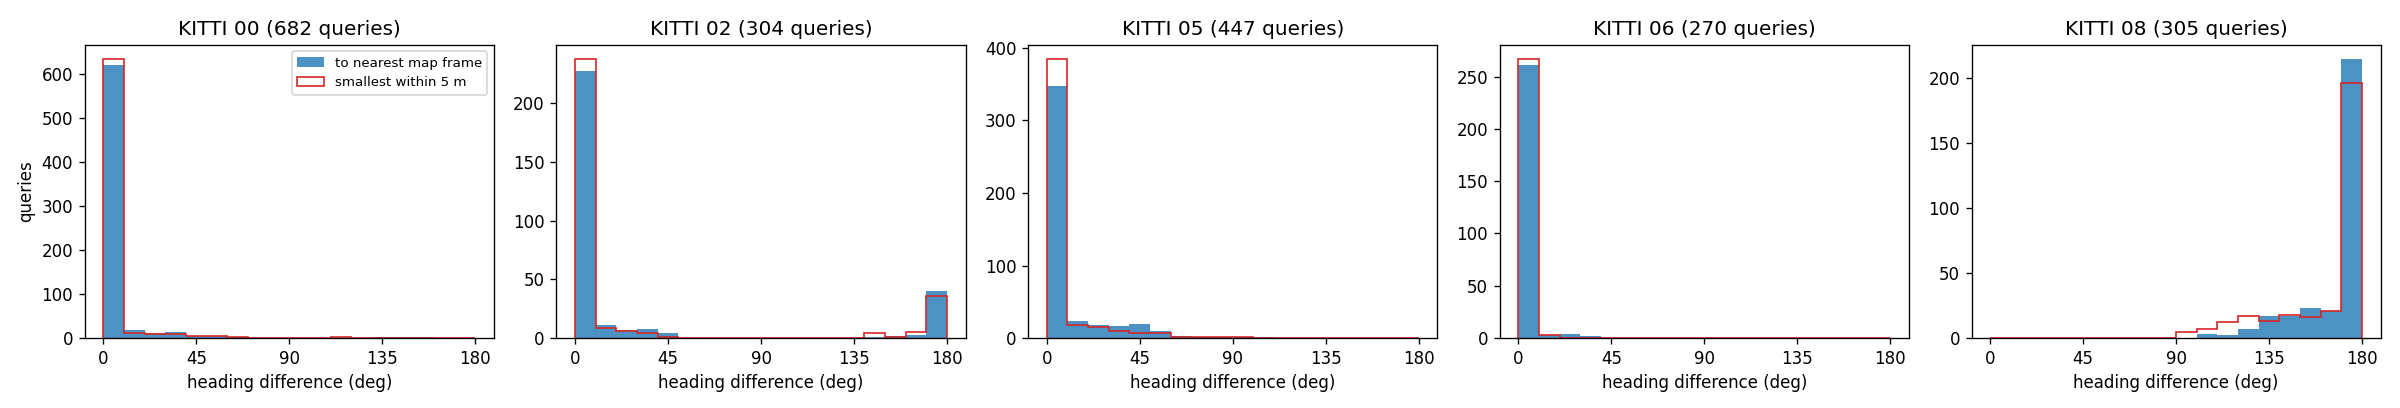

tnet | 2026-10-12_e39427 | epoch_20
  -> /content/drive/MyDrive/lpr/runs/ndt/2026-10-12_e39427/eval/tnet/epoch_20 
 angle  T_dev_I  T_det  T_static  T_follow  T_yaw_deg  desc_drift  self_top1
   0.0   1.7543 0.8978    0.0000    0.0000     0.0000      0.0000      1.000
  15.0   1.7580 0.8963    0.0025    0.0780     0.0011      0.1193      1.000
  30.0   1.7615 0.8948    0.0064    0.1546     0.0028      0.2180      0.995
  45.0   1.7619 0.8946    0.0085    0.2285     0.0041      0.2759      0.990
  60.0   1.7621 0.8946    0.0069    0.2984     0.0026      0.2914      0.980
  90.0   1.7545 0.8978    0.0011    0.4226     0.0002      0.2932      0.990
 120.0   1.7590 0.8958    0.0069    0.5171     0.0043      0.3176      0.990
 150.0   1.7619 0.8947    0.0070    0.5764     0.0040      0.3157      0.955
 180.0   1.7536 0.8981    0.0012    0.5977    -0.0006      0.2975      0.945



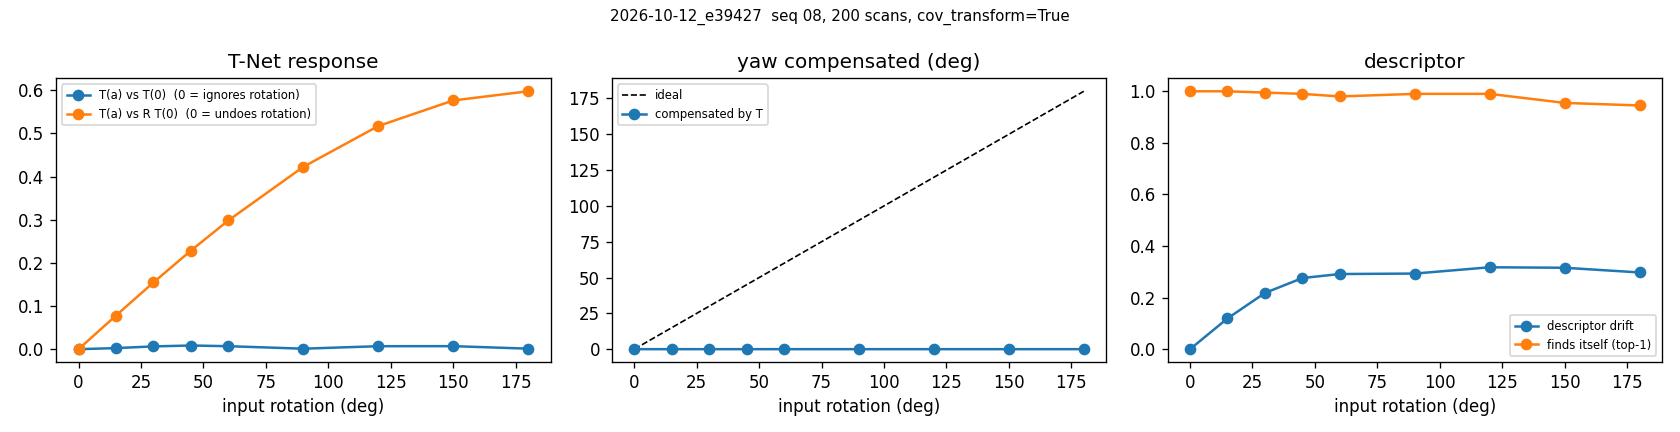

compass | 2026-10-12_e39427 | epoch_20
  00: evaluating 6 compass errors
  02: evaluating 6 compass errors
  05: evaluating 6 compass errors
  06: evaluating 6 compass errors
  08: evaluating 6 compass errors
  -> /content/drive/MyDrive/lpr/runs/ndt/2026-10-12_e39427/eval/compass/epoch_20 
 sigma_deg seq    R@1    R@5   R@1%  queries  median_diff_nearest_deg  median_diff_min_deg  % same (<45)  R@1 same (<45)  % crossing (45-135)  R@1 crossing (45-135)  % opposite (>135)  R@1 opposite (>135)
         0  00  97.95  98.97  99.85      682                      1.0                  0.3          97.8            98.7                  1.5                   90.0                0.7                 20.0
         0  02  91.78  96.71 100.00      304                      0.5                  0.2          84.2            99.2                  0.7                    0.0               15.1                 54.3
         0  05  92.39  94.85  95.53      447                      0.8                  0.2    

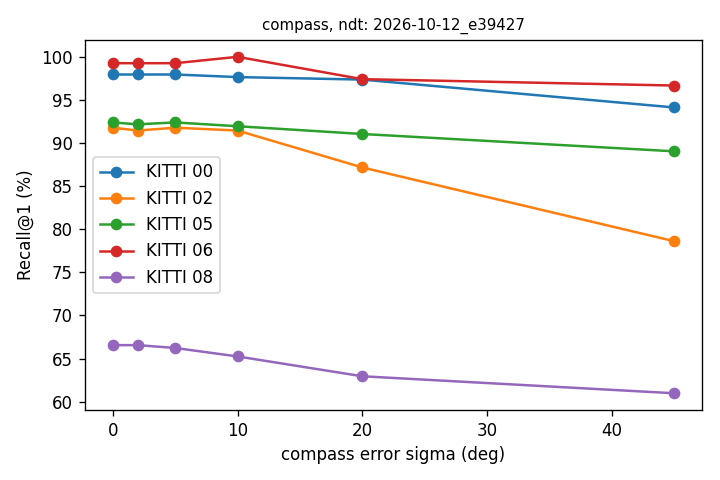

In [ ]:
import pandas as pd
from IPython.display import Image, display

def run_evals(method, run_dir, ckpt, data_dir):
    """Every type in EVALS on one checkpoint; results in <run_dir>/eval/<type>/<checkpoint>/."""
    for e in EVALS:
        if method not in ev.EVAL_TYPES[e]["methods"]:
            continue
        res = subprocess.run(["python", "scripts/evaluate.py", "--method", method, "--run_dir", run_dir,
                              "--ckpt", ckpt, "--eval_type", e, "--data_dir", data_dir, "--kitti_root", KITTI],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout if res.returncode == 0 else res.stdout[-2000:] + res.stderr[-3000:])
        if res.returncode == 0:
            out = ev.eval_dir(run_dir, e, ev.resolve_ckpt(run_dir, ckpt))
            for png in sorted(glob.glob(f"{out}/*.png")):
                display(Image(png))

if MODE == "smoke":
    print("skipped (MODE = smoke)")
elif not glob.glob(f"{RUN_DIR}/epoch_*.pth"):
    print("no checkpoint in", RUN_DIR)
else:
    run_evals("ndt", RUN_DIR, EVAL_CKPT, NDT)

## 10. Tables of all runs and evaluations, training curves

,method,run,status,variant,gpu,started,commit,lr,epochs,negatives,...,eval_02_R@1%,eval_05_R@1,eval_05_R@1%,eval_06_R@1,eval_06_R@1%,eval_08_R@1,eval_08_R@1%,pre_voxel,pre_res,pre_max_count
0,ndt,2026-10-04_baseline_4ed638,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-04,63d57d2,0.00001,20.0,18.0,...,83.55,89.49,91.28,98.52,100.00,4.26,6.89,NaN,NaN,NaN
1,ndt,2026-10-06_cov_transform_5c90e2,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-06T07:42:29,25fb722,0.00001,20.0,18.0,...,82.89,89.93,93.06,98.89,99.63,5.25,10.82,NaN,NaN,NaN
2,ndt,2026-10-07_f60015,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-07T15:20:26,101156f,0.00001,20.0,18.0,...,97.37,92.17,95.97,100.00,100.00,55.74,86.23,NaN,NaN,NaN
3,ndt,2026-10-12_e39427,finished,2026-10-04_baseline_717e81,Tesla T4,2026-10-12T01:05:03,4471fe6,0.00001,20.0,18.0,...,97.04,91.28,96.42,99.26,100.00,51.48,81.31,NaN,NaN,NaN
4,bev,2026-10-05_baseline_4ac7d1,running,2026-10-05_baseline_7711ab,Tesla T4,2026-10-05T18:13:10,d2c8f71,0.00010,20.0,10.0,...,100.00,98.43,99.55,100.00,100.00,91.15,99.34,0.4,0.4,10.0
5,bev,2026-10-08_without_Rein_b14094,finished,2026-10-05_baseline_7711ab,Tesla T4,2026-10-08T08:50:15,af592a7,0.00010,20.0,10.0,...,83.22,90.83,93.51,98.15,100.00,1.31,9.84,0.4,0.4,10.0
6,bev,2026-10-08_without_Rein_with_rot_216fa5,finished,2026-10-05_baseline_7711ab,Tesla T4,2026-10-08T13:44:36,d0175ee,0.00010,20.0,10.0,...,100.00,98.66,99.33,99.63,100.00,91.15,99.02,0.4,0.4,10.0
7,bev,official_2026-10-05_baseline_7711ab,finished,2026-10-05_baseline_7711ab,NaN,NaN,NaN,NaN,NaN,NaN,...,100.00,97.54,98.66,100.00,100.00,94.10,99.67,0.4,0.4,10.0


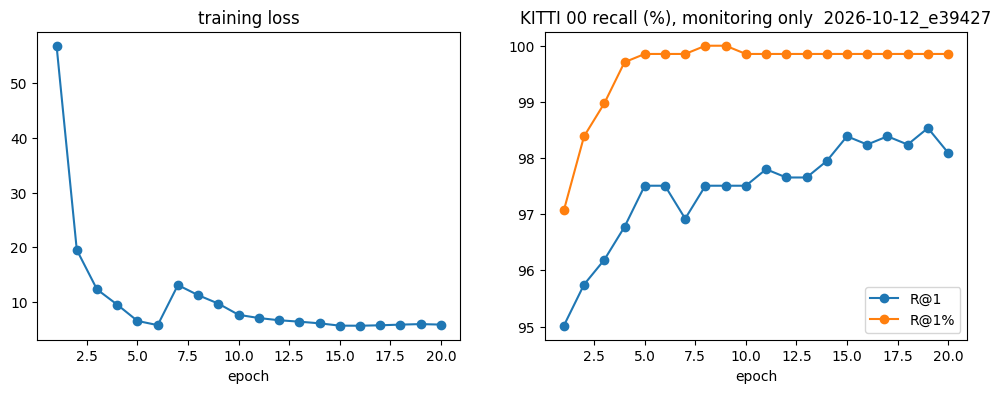

In [ ]:
import matplotlib.pyplot as plt
!python scripts/summarize_runs.py --drive {DRIVE} > /dev/null
display(pd.read_csv(f"{DRIVE}/runs_summary.csv", dtype={"run": str}))
if os.path.exists(f"{RUN_DIR}/metrics.csv"):
    m = pd.read_csv(f"{RUN_DIR}/metrics.csv").drop_duplicates("epoch", keep="last")
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(m.epoch, m.train_loss, marker="o"); ax[0].set_title("training loss"); ax[0].set_xlabel("epoch")
    if "R@1" in m:
        ax[1].plot(m.epoch, m["R@1"], marker="o", label="R@1"); ax[1].plot(m.epoch, m["R@1%"], marker="o", label="R@1%")
    ax[1].set_title(f"KITTI {SEQ} recall (%), monitoring only  {RUN}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

## 11. NDT-Transformer vs BEVPlace++ (every run with a `seqs_heading` evaluation)

In [ ]:
p = f"{DRIVE}/evals_summary.csv"
if os.path.exists(p):
    e = pd.read_csv(p, dtype={"seq": str, "run": str, "checkpoint": str})
    sh = e[e.eval_type == "seqs_heading"]
    print("Recall@1 per sequence")
    display(sh.pivot_table(index=["method", "run", "checkpoint"], columns="seq", values="R@1"))
    cols = [c for c in sh.columns if c.startswith("R@1 ")]
    for s in ("02", "08"):
        print(f"KITTI {s}: Recall@1 per heading group (share of queries in the % columns)")
        g = sh[sh.seq == s].set_index(["method", "run", "checkpoint"])
        display(g[[c for c in g.columns if c.startswith("% ")] + cols])
    cp = e[e.eval_type == "compass"]
    if len(cp):
        print("Compass: Recall@1 per sequence (columns) and compass error sigma in degrees (rows)")
        display(cp.pivot_table(index=["method", "run", "checkpoint", "sigma_deg"], columns="seq", values="R@1"))
    tn = e[e.eval_type == "tnet"]
    if len(tn):
        print("T-Net check (scans rotated by 'angle')")
        display(tn.dropna(axis=1, how="all").set_index(["run", "checkpoint", "angle"])
                .drop(columns=["method", "eval_type", "complete", "seq"], errors="ignore"))

Recall@1 per sequence


seq                                                            00     02  \
method run                                     checkpoint                  
bev    2026-10-05_baseline_4ac7d1              epoch_18     99.85  99.34   
       2026-10-08_without_Rein_b14094          epoch_20     96.19  80.26   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    100.00  98.03   
       official_2026-10-05_baseline_7711ab     model_best  100.00  99.01   
ndt    2026-10-04_baseline_4ed638              epoch_20     95.31  80.26   
       2026-10-06_cov_transform_5c90e2         epoch_20     95.45  80.59   
       2026-10-07_f60015                       epoch_20     97.36  85.53   
       2026-10-12_e39427                       epoch_20     98.09  84.21   

seq                                                           05      06  \
method run                                     checkpoint                  
bev    2026-10-05_baseline_4ac7d1              epoch_18    98.43  100.00   
       2026-10-08_without_Rein_b14094          epoch_20    90.83   98.15   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    98.66   99.63   
       official_2026-10-05_baseline_7711ab     model_best  97.54  100.00   
ndt    2026-10-04_baseline_4ed638              epoch_20    89.49   98.52   
       2026-10-06_cov_transform_5c90e2         epoch_20    89.93   98.89   
       2026-10-07_f60015                       epoch_20    92.17  100.00   
       2026-10-12_e39427                       epoch_20    91.28   99.26   

seq                                                           08  
method run                                     checkpoint         
bev    2026-10-05_baseline_4ac7d1              epoch_18    91.15  
       2026-10-08_without_Rein_b14094          epoch_20     1.31  
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20    91.15  
       official_2026-10-05_baseline_7711ab     model_best  94.10  
ndt    2026-10-04_baseline_4ed638              epoch_20     4.26  
       2026-10-06_cov_transform_5c90e2         epoch_20     5.25  
       2026-10-07_f60015                       epoch_20    55.74  
       2026-10-12_e39427                       epoch_20    51.48

KITTI 02: Recall@1 per heading group (share of queries in the % columns)


% same (<45)  \
method run                                     checkpoint                 
ndt    2026-10-04_baseline_4ed638              epoch_20            84.2   
       2026-10-06_cov_transform_5c90e2         epoch_20            84.2   
       2026-10-07_f60015                       epoch_20            84.2   
       2026-10-12_e39427                       epoch_20            84.2   
bev    2026-10-05_baseline_4ac7d1              epoch_18            84.2   
       2026-10-08_without_Rein_b14094          epoch_20            84.2   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20            84.2   
       official_2026-10-05_baseline_7711ab     model_best          84.2   

                                                           % crossing (45-135)  \
method run                                     checkpoint                        
ndt    2026-10-04_baseline_4ed638              epoch_20                    0.7   
       2026-10-06_cov_transform_5c90e2         epoch_20                    0.7   
       2026-10-07_f60015                       epoch_20                    0.7   
       2026-10-12_e39427                       epoch_20                    0.7   
bev    2026-10-05_baseline_4ac7d1              epoch_18                    0.7   
       2026-10-08_without_Rein_b14094          epoch_20                    0.7   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20                    0.7   
       official_2026-10-05_baseline_7711ab     model_best                  0.7   

                                                           % opposite (>135)  \
method run                                     checkpoint                      
ndt    2026-10-04_baseline_4ed638              epoch_20                 15.1   
       2026-10-06_cov_transform_5c90e2         epoch_20                 15.1   
       2026-10-07_f60015                       epoch_20                 15.1   
       2026-10-12_e39427                       epoch_20                 15.1   
bev    2026-10-05_baseline_4ac7d1              epoch_18                 15.1   
       2026-10-08_without_Rein_b14094          epoch_20                 15.1   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20                 15.1   
       official_2026-10-05_baseline_7711ab     model_best               15.1   

                                                           R@1 same (<45)  \
method run                                     checkpoint                   
ndt    2026-10-04_baseline_4ed638              epoch_20              95.3   
       2026-10-06_cov_transform_5c90e2         epoch_20              95.7   
       2026-10-07_f60015                       epoch_20              96.9   
       2026-10-12_e39427                       epoch_20              96.5   
bev    2026-10-05_baseline_4ac7d1              epoch_18              99.6   
       2026-10-08_without_Rein_b14094          epoch_20              95.3   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20              98.4   
       official_2026-10-05_baseline_7711ab     model_best            99.6   

                                                           R@1 crossing (45-135)  \
method run                                     checkpoint                          
ndt    2026-10-04_baseline_4ed638              epoch_20                      0.0   
       2026-10-06_cov_transform_5c90e2         epoch_20                      0.0   
       2026-10-07_f60015                       epoch_20                      0.0   
       2026-10-12_e39427                       epoch_20                      0.0   
bev    2026-10-05_baseline_4ac7d1              epoch_18                    100.0   
       2026-10-08_without_Rein_b14094          epoch_20                      0.0   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20                     50.0   
       official_2026-10-05_baseline_7711ab     model_best                   50.0   

                                                           R@1 opposite (>

KITTI 08: Recall@1 per heading group (share of queries in the % columns)


% same (<45)  \
method run                                     checkpoint                 
ndt    2026-10-04_baseline_4ed638              epoch_20             0.0   
       2026-10-06_cov_transform_5c90e2         epoch_20             0.0   
       2026-10-07_f60015                       epoch_20             0.0   
       2026-10-12_e39427                       epoch_20             0.0   
bev    2026-10-05_baseline_4ac7d1              epoch_18             0.0   
       2026-10-08_without_Rein_b14094          epoch_20             0.0   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20             0.0   
       official_2026-10-05_baseline_7711ab     model_best           0.0   

                                                           % crossing (45-135)  \
method run                                     checkpoint                        
ndt    2026-10-04_baseline_4ed638              epoch_20                    6.6   
       2026-10-06_cov_transform_5c90e2         epoch_20                    6.6   
       2026-10-07_f60015                       epoch_20                    6.6   
       2026-10-12_e39427                       epoch_20                    6.6   
bev    2026-10-05_baseline_4ac7d1              epoch_18                    6.6   
       2026-10-08_without_Rein_b14094          epoch_20                    6.6   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20                    6.6   
       official_2026-10-05_baseline_7711ab     model_best                  6.6   

                                                           % opposite (>135)  \
method run                                     checkpoint                      
ndt    2026-10-04_baseline_4ed638              epoch_20                 93.4   
       2026-10-06_cov_transform_5c90e2         epoch_20                 93.4   
       2026-10-07_f60015                       epoch_20                 93.4   
       2026-10-12_e39427                       epoch_20                 93.4   
bev    2026-10-05_baseline_4ac7d1              epoch_18                 93.4   
       2026-10-08_without_Rein_b14094          epoch_20                 93.4   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20                 93.4   
       official_2026-10-05_baseline_7711ab     model_best               93.4   

                                                           R@1 same (<45)  \
method run                                     checkpoint                   
ndt    2026-10-04_baseline_4ed638              epoch_20               NaN   
       2026-10-06_cov_transform_5c90e2         epoch_20               NaN   
       2026-10-07_f60015                       epoch_20               NaN   
       2026-10-12_e39427                       epoch_20               NaN   
bev    2026-10-05_baseline_4ac7d1              epoch_18               NaN   
       2026-10-08_without_Rein_b14094          epoch_20               NaN   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20               NaN   
       official_2026-10-05_baseline_7711ab     model_best             NaN   

                                                           R@1 crossing (45-135)  \
method run                                     checkpoint                          
ndt    2026-10-04_baseline_4ed638              epoch_20                      0.0   
       2026-10-06_cov_transform_5c90e2         epoch_20                      0.0   
       2026-10-07_f60015                       epoch_20                     35.0   
       2026-10-12_e39427                       epoch_20                     45.0   
bev    2026-10-05_baseline_4ac7d1              epoch_18                     65.0   
       2026-10-08_without_Rein_b14094          epoch_20                      0.0   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20                     95.0   
       official_2026-10-05_baseline_7711ab     model_best                   75.0   

                                                           R@1 opposite (>

Compass: Recall@1 per sequence (columns) and compass error sigma in degrees (rows)


seq                                                                      00  \
method run                                     checkpoint sigma_deg           
bev    2026-10-08_without_Rein_b14094          epoch_20   0.0         99.85   
                                                          2.0         99.85   
                                                          5.0         99.85   
                                                          10.0        99.27   
                                                          20.0        88.42   
                                                          45.0        56.60   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20   0.0        100.00   
                                                          2.0        100.00   
                                                          5.0        100.00   
                                                          10.0        99.85   
                                                          20.0       100.00   
                                                          45.0        99.85   
       official_2026-10-05_baseline_7711ab     model_best 0.0         99.85   
                                                          2.0         99.85   
                                                          5.0         99.85   
                                                          10.0        99.85   
                                                          20.0        99.85   
                                                          45.0        99.85   
ndt    2026-10-06_cov_transform_5c90e2         epoch_20   0.0         98.68   
                                                          2.0         98.97   
                                                          5.0         98.68   
                                                          10.0        95.31   
                                                          20.0        75.07   
                                                          45.0        43.55   
       2026-10-07_f60015                       epoch_20   0.0         98.24   
                                                          2.0         98.39   
                                                          5.0         98.09   
                                                          10.0        98.09   
                                                          20.0        97.95   
                                                          45.0        96.92   
       2026-10-12_e39427                       epoch_20   0.0         97.95   
                                                          2.0         97.95   
                                                          5.0         97.95   
                                                          10.0        97.65   
                                                          20.0        97.36   
                                                          45.0        94.13   

seq                                                                     02  \
method run                                     checkpoint sigma_deg          
bev    2026-10-08_without_Rein_b14094          epoch_20   0.0        98.68   
                                                          2.0        98.36   
                                                          5.0        95.07   
                                                          10.0       90.46   
                                                          20.0       71.38   
                                                          45.0       38.16   
       2026-10-08_without_Rein_with_rot_216fa5 epoch_20   0.0        99.01   
                                                          2.0        98.68   
                                                          5.0        97.70   
                                                          10.0       98.03   
                                                          20.

T-Net check (scans rotated by 'angle')


T_dev_I   T_det  T_static  \
run                             checkpoint angle                              
2026-10-06_cov_transform_5c90e2 epoch_20   0.0     1.2533  3.2437    0.0000   
                                           15.0    1.2523  3.2416    0.0031   
                                           30.0    1.2462  3.2277    0.0072   
                                           45.0    1.2375  3.2077    0.0105   
                                           60.0    1.2307  3.1919    0.0118   
                                           90.0    1.2224  3.1724    0.0124   
                                           120.0   1.2386  3.2105    0.0123   
                                           150.0   1.2553  3.2490    0.0077   
                                           180.0   1.2555  3.2488    0.0048   
2026-10-07_f60015               epoch_20   0.0     1.9174  1.0655    0.0000   
                                           15.0    1.9174  1.0655    0.0007   
                                           30.0    1.9163  1.0658    0.0012   
                                           45.0    1.9150  1.0663    0.0016   
                                           60.0    1.9150  1.0663    0.0017   
                                           90.0    1.9156  1.0662    0.0016   
                                           120.0   1.9136  1.0669    0.0017   
                                           150.0   1.9158  1.0661    0.0015   
                                           180.0   1.9165  1.0658    0.0019   
2026-10-12_e39427               epoch_20   0.0     1.7543  0.8978    0.0000   
                                           15.0    1.7580  0.8963    0.0025   
                                           30.0    1.7615  0.8948    0.0064   
                                           45.0    1.7619  0.8946    0.0085   
                                           60.0    1.7621  0.8946    0.0069   
                                           90.0    1.7545  0.8978    0.0011   
                                           120.0   1.7590  0.8958    0.0069   
                                           150.0   1.7619  0.8947    0.0070   
                                           180.0   1.7536  0.8981    0.0012   

                                                  T_follow  T_yaw_deg  \
run                             checkpoint angle                        
2026-10-06_cov_transform_5c90e2 epoch_20   0.0      0.0000     0.0000   
                                           15.0     0.1649     0.0000   
                                           30.0     0.3268    -0.0003   
                                           45.0     0.4829    -0.0007   
                                           60.0     0.6305    -0.0010   
                                           90.0     0.8911    -0.0012   
                                           120.0    1.0926    -0.0009   
                                           150.0    1.2202    -0.0003   
                                           180.0    1.2633    -0.0000   
2026-10-07_f60015               epoch_20   0.0      0.0000    -0.0000   
                                           15.0     0.0764     0.0002   
                                           30.0     0.1515     0.0027   
                                           45.0     0.2240     0.0065   
                                           60.0     0.2927     0.0073   
                                           90.0     0.4139     0.0036   
                                           120.0    0.5071     0.0087   
                                           150.0    0.5654     0.0051   
                                           180.0    0.5853     0.0011   
2026-10-12_e39427               epoch_20   0.0      0.0000     0.0000   
                                           15.0     0.0780     0.0011   
                                           30.0     0.1546     0.0028   
                                           45.0     0.2285     0.0041   
      